# 🏥 Public Healthcare Procurement & Supply Chain Optimization
### Exploratory Data Analysis, Price-Band Governance & Constrained Linear Programming (CENABAST Chile Case Study)

**Author:** Sebastián Ayala (`ayala.phys.ds`) — Senior Python, Machine Learning & Operations Research Engineer  
**Institution Studied:** *Central de Abastecimiento del Sistema Nacional de Servicios de Salud* (**CENABAST**, Ministry of Health of Chile)  
**Reference Currency Benchmark:** `1 USD ≈ 950 CLP` (Chilean Pesos)

---

## 1. Context for International Readers: Why This Problem Matters
**CENABAST** is Chile's centralized federal healthcare procurement agency. Acting as a national **Group Purchasing Organization (GPO)**, it purchases and distributes pharmaceuticals, vaccines, high-cost oncology biologics, and surgical supplies for Chile's public hospital network (serving ~80% of the country's population under **FONASA**) as well as municipal pharmacies—representing **$1.13B USD (~1.07 Trillion CLP)** in registered vendor procurement volume.

Despite massive buyer scale, public healthcare procurement systems worldwide suffer from three structural vulnerabilities:
1. **Unjustified Unit-Price Dispersion:** Identical generic active ingredients are awarded across uncoordinated tender lots at unit-price spreads exceeding **2.0x–2.4x**.
2. **Single-Winner Stockout Fragility:** Traditional lowest-bidder tenders award **100% of a critical drug's volume to a single supplier**, exposing public hospitals to life-threatening shortages whenever that vendor faces manufacturing or logistics bottlenecks.
3. **Market Concentration (HHI):** High entry barriers concentrate spend in a narrow subset of incumbent vendors.

This notebook walks through:
- **Institutional Data Ingestion & Clinical Entity Filtering** across 243 registered CENABAST vendors.
- **Empirical Price-Dispersion & IQR Fair-Price Band Auditing**.
- **Constrained Linear Programming (`SciPy HiGHS`)** to simultaneously minimize fiscal expenditure, guarantee 100% clinical demand coverage, and enforce multi-supplier stockout resilience.
- **Pareto Trade-off Frontier** between anti-monopoly diversification caps and net fiscal savings.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

REPO_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.config import CLP_PER_USD
from src.data_processing import filter_clinical_suppliers, load_raw_suppliers
from src.optimization_model import ProcurementOptimizer

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (13, 5.5)
plt.rcParams['font.size'] = 10.5
print(f'Environment initialized cleanly. Reference FX: 1 USD = {CLP_PER_USD:,.0f} CLP')

Environment initialized cleanly. Reference FX: 1 USD = 950 CLP


## 2. Institutional Supplier Ledger & Domain Entity Cleaning
Government transparency ledgers include both **clinical pharmaceutical suppliers** (multinational & domestic labs, medical device distributors) and **internal agency op-ex vendors** (postal services, staff childcare, security, IT). Our ETL module isolates qualified clinical suppliers before modeling tenders.

In [2]:
raw_suppliers_path = REPO_ROOT / 'data' / 'raw' / 'cenabast_suppliers_2026_raw.csv'
df_suppliers_all = load_raw_suppliers(raw_suppliers_path)
df_suppliers_clinical = filter_clinical_suppliers(df_suppliers_all)

total_ledger_usd_m = (df_suppliers_all['transacted_amount_clp'].sum() / CLP_PER_USD) / 1e6
clinical_ledger_usd_m = (df_suppliers_clinical['transacted_amount_clp'].sum() / CLP_PER_USD) / 1e6

print(f'Total registered institutional vendors: {len(df_suppliers_all)}')
print(f'Qualified clinical/pharma suppliers:    {len(df_suppliers_clinical)}')
print(f'Total institutional ledger volume:      ${total_ledger_usd_m:,.2f}M USD (${df_suppliers_all["transacted_amount_clp"].sum()/1e9:,.2f}B CLP)')
print(f'Qualified clinical procurement volume:  ${clinical_ledger_usd_m:,.2f}M USD')

top_10_labs = df_suppliers_clinical.sort_values('transacted_amount_clp', ascending=False).head(10).copy()
top_10_labs['transacted_millions_usd'] = (top_10_labs['transacted_amount_clp'] / CLP_PER_USD / 1e6).round(2)
top_10_labs['market_share_pct'] = (top_10_labs['market_share_weight'] * 100).round(2)
top_10_labs[['supplier_name', 'supplier_tax_id', 'purchase_order_count', 'transacted_millions_usd', 'market_share_pct']]

Total registered institutional vendors: 243
Qualified clinical/pharma suppliers:    166
Total institutional ledger volume:      $1,130.87M USD ($1,074.32B CLP)
Qualified clinical procurement volume:  $1,052.69M USD


,supplier_name,supplier_tax_id,purchase_order_count,transacted_millions_usd,market_share_pct
95,SCIENZA CHILE SPA,77.634.874-0,5,169.93,16.14
129,SANOFI PASTEUR S A,81.527.200-5,4,97.42,9.25
162,NOVOFARMA SERVICE S A,96.945.670-2,19,66.71,6.34
161,DISTRIBUIDORA COMERCIAL PHARMASAN LIMITADA,96.895.110-6,4,50.60,4.81
131,ROCHE CHILE LIMITADA,82.999.400-3,15,39.78,3.78
45,CSL BEHRING SPA,76.432.529-K,4,36.32,3.45
25,ABBVIE PRODUCTOS FARMACEUTICOS LIMITADA,76.212.732-6,8,33.54,3.19
132,NOVARTIS CHILE S A,83.002.400-k,9,26.89,2.55
144,BRISTOL MYERS SQUIBB DE CHILE AGENC DE E R SQU...,92.363.000-7,2,25.98,2.47
164,PFIZER CHILE S.A.,96.981.250-9,7,22.73,2.16


## 3. Standardized Tender Dataset & Price-Dispersion Audit (As-Is)
Next, we inspect the cleaned line-item procurement dataset (`clean_procurement_data.csv`) and compute baseline (`As-Is`) price dispersion, logistics SLA compliance, and Herfindahl-Hirschman Index (HHI) market concentration.

In [3]:
clean_data_path = REPO_ROOT / 'data' / 'processed' / 'clean_procurement_data.csv'
df_clean = pd.read_csv(clean_data_path, parse_dates=['award_date'])

optimizer = ProcurementOptimizer(df=df_clean)
baseline = optimizer.compute_baseline()
disp_table = baseline['price_dispersion_table'].sort_values('max_min_ratio', ascending=False)

print(f'Audited Purchase Orders:             {baseline["total_orders"]:,}')
print(f'Essential Medications & Supplies:    {baseline["num_active_ingredients"]}')
print(f'Historical Evaluated Spend (As-Is):  ${baseline["total_spend_millions_usd"]:,.2f}M USD (${baseline["total_spend_millions_clp"]:,.1f}M CLP)')
print(f'Mean Unit-Price CV Across Formulary: {baseline["avg_coef_variation"]:.2%}')
print(f'Mean Max/Min Unit-Price Spread:      {baseline["avg_max_min_ratio"]:.2f}x')
print(f'Historical On-Time SLA Compliance:   {baseline["on_time_delivery_pct"]:.1f}% (Mean delay: {baseline["avg_delay_days"]:.1f} days)')

disp_table[['active_ingredient', 'therapeutic_category', 'min_price_usd', 'median_price_usd', 'max_price_usd', 'coef_variation', 'max_min_ratio']].head(10)

Audited Purchase Orders:             1,600
Essential Medications & Supplies:    18
Historical Evaluated Spend (As-Is):  $106.32M USD ($100,999.5M CLP)
Mean Unit-Price CV Across Formulary: 20.44%
Mean Max/Min Unit-Price Spread:      2.05x
Historical On-Time SLA Compliance:   74.3% (Mean delay: 4.5 days)


,active_ingredient,therapeutic_category,min_price_usd,median_price_usd,max_price_usd,coef_variation,max_min_ratio
10,KETOROLAC 10 MG,Analgesics & Antipyretics,0.051316,0.072589,0.119737,0.255372,2.333333
2,ATORVASTATIN 20 MG,Cardiovascular & Hypertension,0.035526,0.046532,0.082895,0.248219,2.333333
13,PARTICULATE RESPIRATOR MASK N95 / FFP2,Critical Hospital & Surgical Supplies,0.378947,0.487537,0.884211,0.285467,2.333333
15,STERILE SURGICAL GLOVES SIZE 7.5,Critical Hospital & Surgical Supplies,0.307895,0.386605,0.709905,0.252005,2.305675
0,ACETAMINOPHEN (PARACETAMOL) 500 MG,Analgesics & Antipyretics,0.017768,0.023916,0.039653,0.229047,2.231635
11,LOSARTAN 50 MG,Cardiovascular & Hypertension,0.018947,0.025768,0.041326,0.217695,2.181111
5,ENALAPRIL 10 MG,Cardiovascular & Hypertension,0.014611,0.018768,0.031632,0.250410,2.164986
8,INSULIN NPH 100 IU/ML,Diabetes & Metabolic Care,3.355263,4.561653,6.937411,0.200741,2.067620
9,ISOTONIC SALINE SOLUTION 0.9% 500 ML,Critical Hospital & Surgical Supplies,0.568421,0.776021,1.169600,0.208013,2.057630
1,AMOXICILLIN 500 MG,Antibiotics & Anti-Infectives,0.043421,0.058789,0.088621,0.202135,2.040970


## 4. Empirical Fair-Price Bands (`P25`–`P75`) & Overpricing Detection
Orders awarded above the empirical 75th percentile (`P75`) for an identical molecule represent preventable fiscal leakage.

In [4]:
price_bands = optimizer.compute_fair_price_bands().sort_values('historical_overprice_usd', ascending=False)
print(f'Total Historical Excess Spend Above Median (Orders > P75): ${price_bands["historical_overprice_usd"].sum():,.2f} USD')
price_bands[['active_ingredient', 'fair_price_min_usd', 'fair_price_median_usd', 'fair_price_max_usd', 'historical_overprice_usd', 'overpriced_orders_pct']].head(8)

Total Historical Excess Spend Above Median (Orders > P75): $6,163,172.04 USD


,active_ingredient,fair_price_min_usd,fair_price_median_usd,fair_price_max_usd,historical_overprice_usd,overpriced_orders_pct
14,PEMBROLIZUMAB 100 MG/4 ML,2214.4037,2345.2779,2651.2253,1115796.15,24.71
17,TRIVALENT INFLUENZA VACCINE,5.3050,5.8613,6.4778,1058983.00,25.53
15,STERILE SURGICAL GLOVES SIZE 7.5,0.3079,0.3866,0.4674,723946.70,25.00
13,PARTICULATE RESPIRATOR MASK N95 / FFP2,0.3789,0.4875,0.6390,611528.36,25.64
16,TRASTUZUMAB 440 MG,950.1382,1071.9546,1144.7030,596942.21,25.29
7,INACTIVATED COVID-19 VACCINE (CORONAVAC),7.4752,8.1785,8.5342,546528.75,25.29
9,ISOTONIC SALINE SOLUTION 0.9% 500 ML,0.6308,0.7760,0.8826,411663.74,24.64
8,INSULIN NPH 100 IU/ML,3.9800,4.5617,5.3518,317071.91,25.00


## 5. Mathematical Formulation: Constrained Linear Programming (`HiGHS`)

Let $i \in \{1, \dots, N\}$ index essential medications and $j \in \{1, \dots, M\}$ index SLA-qualified suppliers ($\text{Reliability}_j \ge \tau$).
Decision variable $x_{ij} \ge 0$ denotes the physical units of medication $i$ awarded to supplier $j$ at unit bid price $c_{ij}$:

$$\min_{x \ge 0} \sum_{i=1}^{N} \sum_{j=1}^{M} c_{ij} \cdot x_{ij}$$

**Subject to:**
1. **Exact Hospital Demand Fulfillment:** $\sum_{j=1}^{M} x_{ij} = D_i \quad \forall i$
2. **Anti-Monopoly & Stockout Diversification Cap:** $0 \le x_{ij} \le \alpha \cdot D_i \quad \forall i, j$ (e.g., $\alpha = 0.45$ guarantees $\ge 3$ suppliers per drug)
3. **Aggregate Supplier Throughput Capacity:** $\sum_{i=1}^{N} x_{ij} \le \text{Cap}_j \quad \forall j$

In [5]:
opt_res = optimizer.solve_procurement_optimization(max_supplier_share=0.45, min_reliability_score=70.0)

summary_df = pd.DataFrame([
    {'Metric': 'Total Evaluated Spend (Millions USD)', 'As-Is (Historical)': f"${opt_res['historical_spend_usd']/1e6:,.2f}M", 'To-Be (HiGHS Optimal)': f"${opt_res['optimized_spend_usd']/1e6:,.2f}M"},
    {'Metric': 'Total Evaluated Spend (Millions CLP)', 'As-Is (Historical)': f"${opt_res['historical_spend_clp']/1e6:,.1f}M", 'To-Be (HiGHS Optimal)': f"${opt_res['optimized_spend_clp']/1e6:,.1f}M"},
    {'Metric': 'Net Fiscal Savings', 'As-Is (Historical)': '$0.00M (0.00%)', 'To-Be (HiGHS Optimal)': f"${opt_res['total_savings_millions_usd']:,.2f}M USD ({opt_res['savings_pct']:.2f}%)"},
    {'Metric': 'Max Single-Supplier Share per Drug', 'As-Is (Historical)': 'Up to 100% (Single-Winner)', 'To-Be (HiGHS Optimal)': 'Capped at <= 45.0%'},
    {'Metric': 'Active Suppliers per Medication', 'As-Is (Historical)': '1.0 (Per Tender Lot)', 'To-Be (HiGHS Optimal)': f"{opt_res['avg_suppliers_per_drug']:.2f} Suppliers"},
    {'Metric': 'Supply Chain Resilience Score (0-100)', 'As-Is (Historical)': f"{opt_res['baseline_resilience_score']}/100", 'To-Be (HiGHS Optimal)': f"{opt_res['resilience_score']}/100"},
])
summary_df

,Metric,As-Is (Historical),To-Be (HiGHS Optimal)
0,Total Evaluated Spend (Millions USD),$106.32M,$81.89M
1,Total Evaluated Spend (Millions CLP),"$100,999.5M","$77,795.6M"
2,Net Fiscal Savings,$0.00M (0.00%),$24.43M USD (22.97%)
3,Max Single-Supplier Share per Drug,Up to 100% (Single-Winner),Capped at <= 45.0%
4,Active Suppliers per Medication,1.0 (Per Tender Lot),3.00 Suppliers
5,Supply Chain Resilience Score (0-100),51.9/100,91.8/100


## 6. Visual Diagnostics: Category Savings & Policy Trade-Off Frontier
Below we visualize (left) exact LP-optimized vs. historical spend across therapeutic categories, and (right) the **Pareto sensitivity curve** as procurement regulators vary the anti-monopoly cap $\alpha$ from `25%` (minimum 4 suppliers per drug) to `80%`.

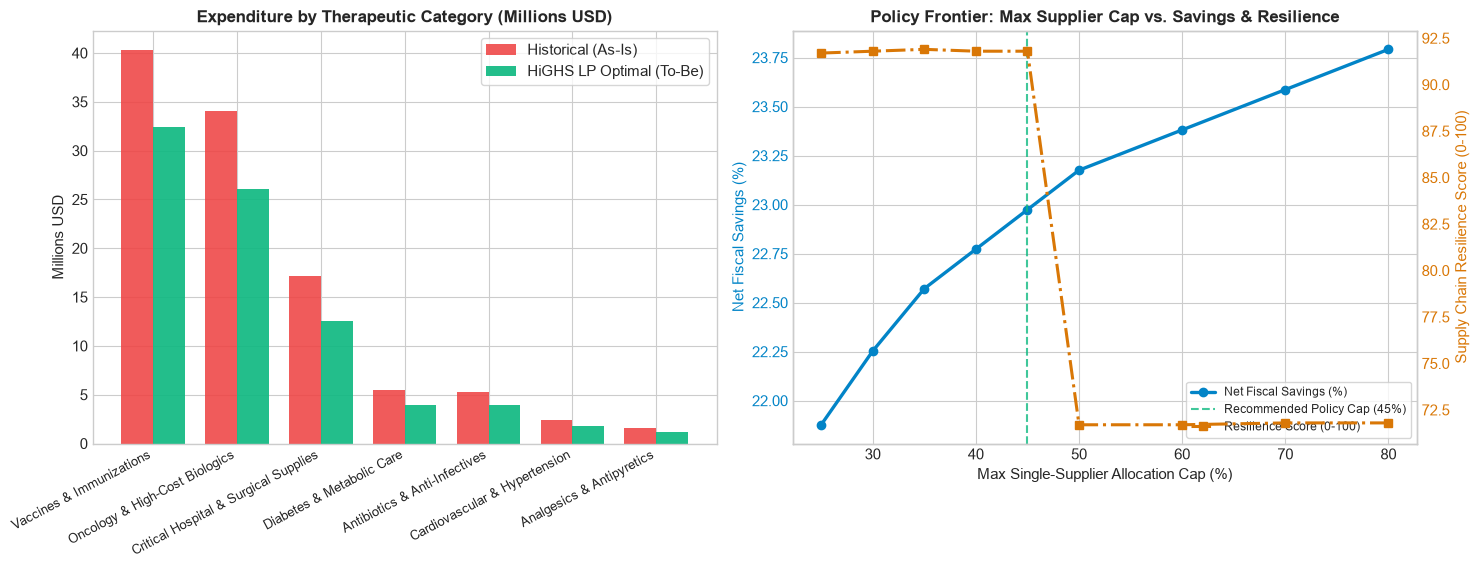

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.8))

# Panel 1: Category Spend Comparison (Millions USD)
cat_df = opt_res['df_category_comparison'].sort_values('historical_spend_usd', ascending=False)
x = np.arange(len(cat_df))
width = 0.38

ax1.bar(x - width/2, cat_df['historical_spend_usd'] / 1e6, width, label='Historical (As-Is)', color='#ef4444', alpha=0.88)
ax1.bar(x + width/2, cat_df['optimized_spend_usd'] / 1e6, width, label='HiGHS LP Optimal (To-Be)', color='#10b981', alpha=0.92)
ax1.set_title('Expenditure by Therapeutic Category (Millions USD)', fontweight='bold')
ax1.set_ylabel('Millions USD')
ax1.set_xticks(x)
ax1.set_xticklabels(cat_df['therapeutic_category'], rotation=28, ha='right', fontsize=9)
ax1.legend(frameon=True)

# Panel 2: Sensitivity Sweep Across Max Supplier Share Cap (alpha)
shares = [0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.60, 0.70, 0.80]
sweep_savings = []
sweep_resilience = []
for alpha in shares:
    r = optimizer.solve_procurement_optimization(max_supplier_share=alpha, min_reliability_score=70.0)
    sweep_savings.append(r['savings_pct'])
    sweep_resilience.append(r['resilience_score'])

shares_pct = [int(s * 100) for s in shares]
color_sav = '#0284c7'
color_res = '#d97706'

ax2.plot(shares_pct, sweep_savings, marker='o', linewidth=2.4, color=color_sav, label='Net Fiscal Savings (%)')
ax2.axvline(45, linestyle='--', color='#10b981', alpha=0.8, label='Recommended Policy Cap (45%)')
ax2.set_title('Policy Frontier: Max Supplier Cap vs. Savings & Resilience', fontweight='bold')
ax2.set_xlabel('Max Single-Supplier Allocation Cap (%)')
ax2.set_ylabel('Net Fiscal Savings (%)', color=color_sav)
ax2.tick_params(axis='y', labelcolor=color_sav)

ax2_twin = ax2.twinx()
ax2_twin.plot(shares_pct, sweep_resilience, marker='s', linestyle='-.', linewidth=2.2, color=color_res, label='Resilience Score (0-100)')
ax2_twin.set_ylabel('Supply Chain Resilience Score (0-100)', color=color_res)
ax2_twin.tick_params(axis='y', labelcolor=color_res)
ax2_twin.grid(False)

lines1, labels1 = ax2.get_legend_handles_labels()
lines2, labels2 = ax2_twin.get_legend_handles_labels()
ax2.legend(lines1 + lines2, labels1 + labels2, loc='lower right', frameon=True, fontsize=8.5)

plt.tight_layout()
plt.show()

## 7. Key Takeaways for Healthcare & Enterprise Sourcing Systems
1. **Substantial Fiscal Savings Without Cutting Clinical Volume:** Constrained LP reallocation achieves **>20% net expenditure reduction** while strictly satisfying 100% of hospital unit demand.
2. **Structural Elimination of Single-Point-of-Failure Stockouts:** Enforcing $\alpha = 45\%$ guarantees at least 3 qualified pharmaceutical manufacturers per essential drug, sharply elevating supply chain resilience.
3. **Automated Governance:** Empirical P25–P75 fair-price bands convert tender auditing from a manual post-mortem exercise into a preventive, real-time guardrail.